# Analyzing ClinVar variants

In [ ]:
import os
import polars as pl
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# import concurrent.futures
# aa_single_to_three = {
#     'A': 'Ala',  # Alanine
#     'R': 'Arg',  # Arginine
#     'N': 'Asn',  # Asparagine
#     'D': 'Asp',  # Aspartic acid
#     'C': 'Cys',  # Cysteine
#     'Q': 'Gln',  # Glutamine
#     'E': 'Glu',  # Glutamic acid
#     'G': 'Gly',  # Glycine
#     'H': 'His',  # Histidine
#     'I': 'Ile',  # Isoleucine
#     'L': 'Leu',  # Leucine
#     'K': 'Lys',  # Lysine
#     'M': 'Met',  # Methionine
#     'F': 'Phe',  # Phenylalanine
#     'P': 'Pro',  # Proline
#     'S': 'Ser',  # Serine
#     'T': 'Thr',  # Threonine
#     'W': 'Trp',  # Tryptophan
#     'Y': 'Tyr',  # Tyrosine
#     'V': 'Val'   # Valine
# }

## Loading the dbnsfp snps

In [3]:
df_clinvar = pl.scan_parquet(f"../3_outputs/processed_data/dbnsfp/dbNSFP5.0a_variant.clin_var_re-annot_pdb_variants.parquet")

# df_clinvar.collect()
# df_clinvar.filter(pl.col("aaalt").str.len_chars() == 1).collect()

# df_clinvar_dup = pl.scan_parquet(f"../3_outputs/processed_data/dbnsfp/dbNSFP5.0a_variant.clin_var_re-annot.parquet")
# df_clinvar_dup.collect()

In [4]:
# Once you’re happy with the behavior on the subset,
# you can apply it to the entire lazy DataFrame.
# Assume ldf is your lazy DataFrame.
# Randomly sample 1000 rows from the exploded DataFrame
# df_clinvar_sampled = df_clinvar_exploded.collect().sample(n=1000)

variant_annot = [
    "hg19_chr","genename","Ensembl_geneid","Ensembl_proteinid",
    "Uniprot_acc","Uniprot_entry",
    "aapos","aaref","aaref_3","aaalt","aaalt_3",#"aa_change",
    "Ensembl_transcriptid","hg19_pos(1-based)","HGVSc_snpEff","HGVSp_snpEff",
    "HGVSc_VEP","HGVSp_VEP",
]
predictor_algos = [
    "PROVEAN_score","PROVEAN_converted_rankscore","PROVEAN_pred",
    "ESM1b_score","ESM1b_rankscore","ESM1b_pred",
    "AlphaMissense_score","AlphaMissense_rankscore","AlphaMissense_pred"
] + [col for col in df_clinvar.collect_schema().names() if "clinvar" in col]

## AI-predictor scores distribution

In [5]:
df_clinvar_sampled_plots = df_clinvar.select(
    pl.col(predictor_algos)
).with_columns(
    pl.col("ESM1b_score").replace(".", None).cast(pl.Float64).alias("esm1b"),
    pl.col("AlphaMissense_score").replace(".", None).cast(pl.Float64).alias("alphamissense"),
    pl.col("PROVEAN_score").replace(".", None).cast(pl.Float64).alias("provean")
).filter((pl.col("clinvar_clnsig_clean")!="4_VUS")&(pl.col("clinvar_clnsig_clean")!="5_Others")).collect()

df_clinvar_sampled_plots

PROVEAN_score,PROVEAN_converted_rankscore,PROVEAN_pred,ESM1b_score,ESM1b_rankscore,ESM1b_pred,AlphaMissense_score,AlphaMissense_rankscore,AlphaMissense_pred,clinvar_id,clinvar_clnsig,clinvar_trait,clinvar_review,clinvar_hgvs,clinvar_var_source,clinvar_MedGen_id,clinvar_OMIM_id,clinvar_Orphanet_id,clinvar_nt_change,clinvar_aa_change,clinvar_clnsig_clean,esm1b,alphamissense,provean
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,cat,f64,f64,f64
"""-0.28""","""0.11479""","""N""","""-5.093""","""0.37878""","""T""","""0.12""","""0.24867""","""B""","""2486768""","""Likely_benign""","""not_specified""","""criteria_provided,_single_subm…","""NC_000021.9:g.13630977G>A""",""".""","""CN169374""",""".""",""".""","""1279G>A ""","""Val427Met""","""2_Benign""",-5.093,0.12,-0.28
""".""",""".""",""".""",""".""",""".""",""".""",""".""",""".""",""".""","""1641486""","""Likely_benign""","""not_provided""","""criteria_provided,_single_subm…","""NC_000021.9:g.14109008T>G""",""".""","""C3661900""",""".""",""".""","""1368A>C ""","""Thr456=""","""2_Benign""",null,null,null
"""0.67""","""0.02246""","""N""","""-6.57""","""0.50888""","""T""","""0.059""","""0.00804""","""B""","""2336004""","""Likely_benign""","""not_specified""","""criteria_provided,_single_subm…","""NC_000021.9:g.14227009A>G""",""".""","""CN169374""",""".""",""".""","""562A>G ""","""Lys188Glu""","""2_Benign""",-6.57,0.059,0.67
"""0.98""","""0.01434""","""N""","""-1.991""","""0.03150""","""T""","""0.0597""","""0.00903""","""B""","""3313159""","""Likely_benign""","""not_specified""","""criteria_provided,_single_subm…","""NC_000021.9:g.14227250G>A""",""".""","""CN169374""",""".""",""".""","""803G>A ""","""Cys268Tyr""","""2_Benign""",-1.991,0.0597,0.98
"""-0.25""","""0.10941""","""N""","""-3.62""","""0.18161""","""T""","""0.0714""","""0.04055""","""B""","""2403739""","""Likely_benign""","""not_specified""","""criteria_provided,_single_subm…","""NC_000021.9:g.14373993C>T""",""".""","""CN169374""",""".""",""".""","""1040G>A ""","""Arg347His""","""2_Benign""",-3.62,0.0714,-0.25
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""-3.61""","""0.71557""","""D""","""-9.584""","""0.72126""","""D""","""0.1812""","""0.46558""","""B""","""999931""","""Conflicting_classifications_of…","""Inborn_genetic_diseases|Autoso…","""criteria_provided,_conflicting…","""NC_000007.14:g.129001075G>A""",""".""","""C0950123|C1842062""","""608423""","""55595""","""856C>T ""","""Arg286Cys""","""3_Conflicting""",-9.584,0.1812,-3.61
""".""","""0.71314""",""".""","""-5.134""","""0.38309""","""T""",""".""",""".""",""".""","""999940""","""Uncertain_significance""","""Muscular_dystrophy-dystroglyca…","""criteria_provided,_single_subm…","""NC_000003.12:g.49530984C>G""",""".""","""C4225291|C4511963""","""616538|613818""","""370997|899|280333""","""473C>G ""","""Pro158Arg""","""2_Benign""",-5.134,null,null
"""-1.93""","""0.44859""","""N""","""-5.814""","""0.44935""","""T""","""0.6774""","""0.75623""","""P""","""999973""","""Pathogenic""","""Developmental_and_epileptic_en…","""criteria_provided,_single_subm…","""NC_000009.12:g.135765131G>A""",""".""","""C3554195|C3554306""","""614959|615005""","""293181|98784""","""1136G>A ""","""Ser379Asn""","""1_Pathogenic""",-5.814,0.6774,-1.93


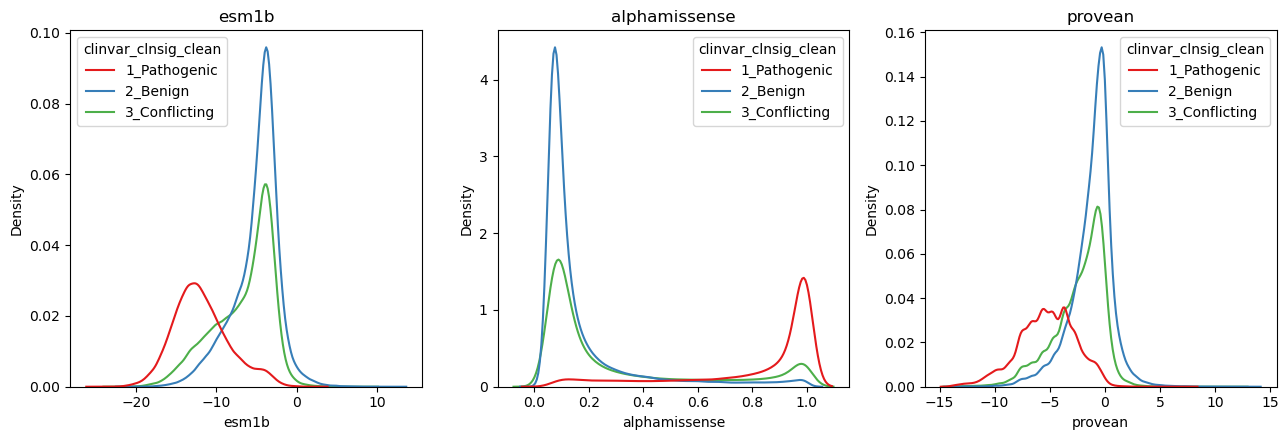

In [5]:
# Define variables to plot
variables = ["esm1b", "alphamissense", "provean"]

# Create a FacetGrid for multiple subplots
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5)) ## , sharey=True
hue_order = sorted(df_clinvar_sampled_plots["clinvar_clnsig_clean"].drop_nulls().unique().to_list())
# Loop through variables and create subplots
for ax, var in zip(axes, variables):
    sns.kdeplot(
        data=df_clinvar_sampled_plots,
        x=var,
        hue="clinvar_clnsig_clean",
        hue_order=hue_order,
        # kde=True,
        ax=ax,
        palette="Set1"
    )
    ax.set_title(var)
    
plt.tight_layout()
plt.show()

## AI-predictor scores across structure

In [7]:
df_clinvar_scores = pl.scan_parquet(f"../3_outputs/processed_data/dbnsfp/dbNSFP5.0a_variant.clin_var_re-annot_pdb_variants_plddt_rsa.parquet")
df_clinvar_scores = df_clinvar_scores.with_columns(
    pl.col("plddt").cast(pl.Float32).alias("plddt_f32"),
    pl.col("rsa").cast(pl.Float32).alias("rsa_f32"),
)

# df_clinvar_scores.collect()
# df_clinvar_scores.filter(~pl.col("plddt_f32").is_nan()).collect()

In [8]:
df_clinvar_w_scores = df_clinvar_scores.filter(
    ~pl.col("plddt_f32").is_nan()
).with_columns(
    (
        pl.when(pl.col("rsa_f32")<.1)
        .then(pl.lit("<10"))
        .when(pl.col("rsa_f32")>=.9)
        .then(pl.lit("$\geqslant$90"))
        .otherwise(pl.lit("10-90"))
    ).alias("rsa_cat"),
    (
        pl.when(pl.col("plddt_f32")<=50)
        .then(pl.lit("<=50"))
        .when((pl.col("plddt_f32")>50)&(pl.col("plddt_f32")<=70))
        .then(pl.lit("50-70"))
        .when((pl.col("plddt_f32")>70)&(pl.col("plddt_f32")<=90))
        .then(pl.lit("70-90"))
        .otherwise(pl.lit(">90"))
    ).alias("plddt_cat"),
    (
        pl.when(pl.col("AlphaMissense_pred").str.contains("B"))
        .then(pl.lit("2_Benign"))
        .when(pl.col("AlphaMissense_pred").str.contains("P"))
        .then(pl.lit("1_Pathogenic"))
        .when(pl.col("AlphaMissense_pred").str.contains("A"))
        .then(pl.lit("3_Ambiguous"))
        .otherwise(pl.lit("."))
    ).alias("AM_pred"),
    (
        pl.when(pl.col("PROVEAN_pred").str.contains("D"))
        .then(pl.lit("1_Damaging"))
        .when(pl.col("PROVEAN_pred").str.contains("N"))
        .then(pl.lit("2_Neutral"))
        .otherwise(pl.lit("."))
    ).alias("Provean_pred"),
    (
        pl.when(pl.col("ESM1b_pred").str.contains("D"))
        .then(pl.lit("1_Deleterious"))
        .when(pl.col("ESM1b_pred").str.contains("T"))
        .then(pl.lit("2_Tolerated"))
        .otherwise(pl.lit("."))
    ).alias("ESM1b_pred")
)

In [9]:
# df_clinvar_w_scores.filter((pl.col("AlphaMissense_pred")!=".")).collect()
# df_clinvar_w_scores.filter((pl.col("clinvar_clnsig_clean")=="1_Pathogenic")).collect()
# df_clinvar_w_scores.filter((pl.col("clinvar_clnsig_clean")=="2_Benign")).collect()

### Percentage of accurate prediction per pLDDT and RSA category

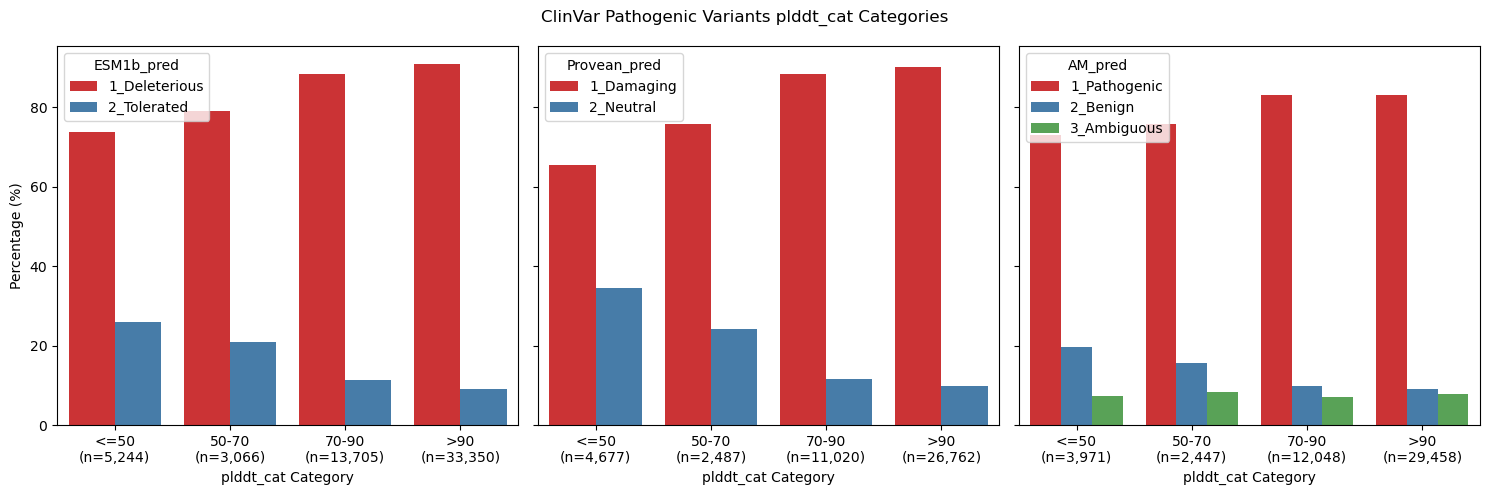

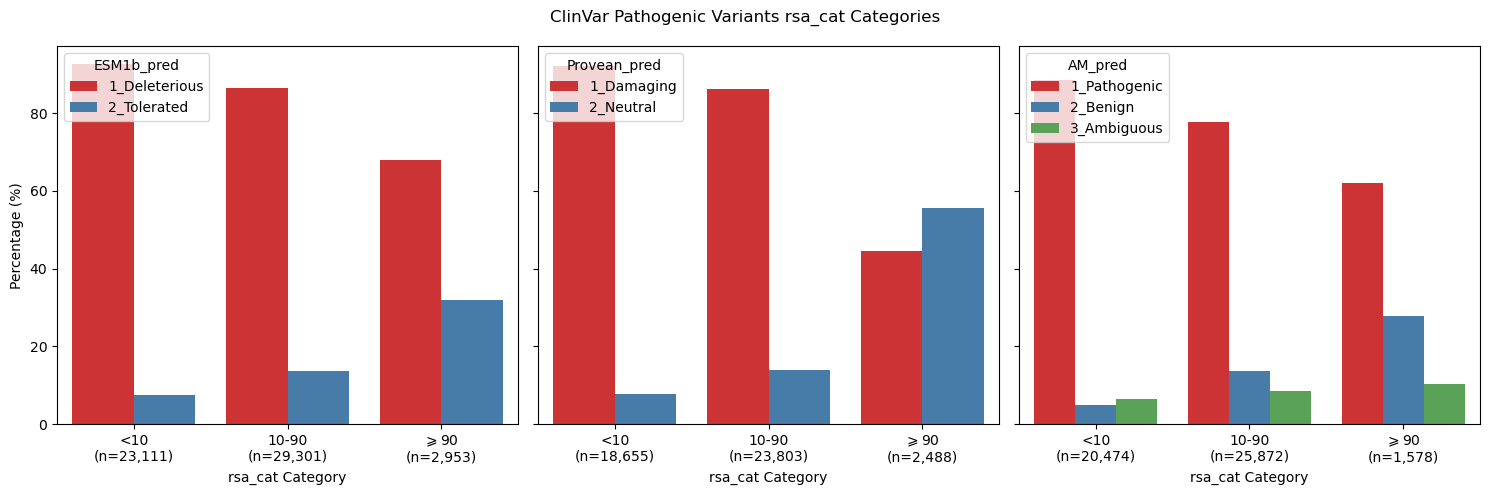

In [ ]:
# First, calculate the percentages for each group
# Group by both categories and calculate the percentage of each alphamissense_pred within each group

pred_cat = {
    # Make sure the categories are in the right order
    "plddt_cat": ["<=50", "50-70", "70-90", ">90"],
    "rsa_cat": ["<10", "10-90", "$\geqslant$90"]
}
preds = ["ESM1b_pred", "Provean_pred", "AM_pred"]

for cat in ["plddt_cat", "rsa_cat"]:
    fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
    for pred in preds:
        percentage_df = (
            df_clinvar_w_scores
            .filter((pl.col("clinvar_clnsig_clean")=="1_Pathogenic")&(pl.col(pred)!="."))
            .group_by([cat, pred]) ##"RSA_cat", 
            .agg(count=pl.len())
            .collect()
            .to_pandas()  # Convert to pandas for easier use with seaborn
        )
        # Calculate percentage within each pLDDT_cat and RSA_cat group
        percentage_df['total'] = percentage_df.groupby([cat])['count'].transform('sum') ##, 'RSA_cat'
        percentage_df['percentage'] = percentage_df['count'] / percentage_df['total'] * 100

        # print(percentage_df)
        
        # Filter for just this RSA category
        subset = percentage_df
        
        # Create the stacked barplot
        sns.barplot(
            x=cat, 
            y="percentage", 
            hue=pred,
            hue_order=sorted(percentage_df[pred].unique()),
            data=subset,
            order=pred_cat[cat],
            palette="Set1",  # You can choose a different color palette,
            ax=axes[preds.index(pred)]
        )
        # Get the current x-tick labels
        current_ticks = axes[preds.index(pred)].get_xticks()
        new_labels = []
        # For each category, add the total count to the label
        for category in pred_cat[cat]:
            # Get the total for this category
            total = subset[subset[cat] == category]['total'].iloc[0]
            # Create new label with category and total
            new_label = f"{category}\n(n={total:,})"
            new_labels.append(new_label)

        # Set the new x-tick labels
        # Explicitly set the tick positions and then the labels
        axes[preds.index(pred)].set_xticks(current_ticks[:len(new_labels)])
        axes[preds.index(pred)].set_xticklabels(new_labels)

        axes[preds.index(pred)].set_xlabel(f"{cat} Category")
        axes[preds.index(pred)].set_ylabel("")
        axes[preds.index(pred)].legend(loc="upper left", title=pred)

    axes[0].set_ylabel("Percentage (%)")
    # plt.legend(title="AlphaMissense Prediction")
    plt.suptitle(f"ClinVar Pathogenic Variants {cat} Categories")
    plt.tight_layout()
    plt.show()

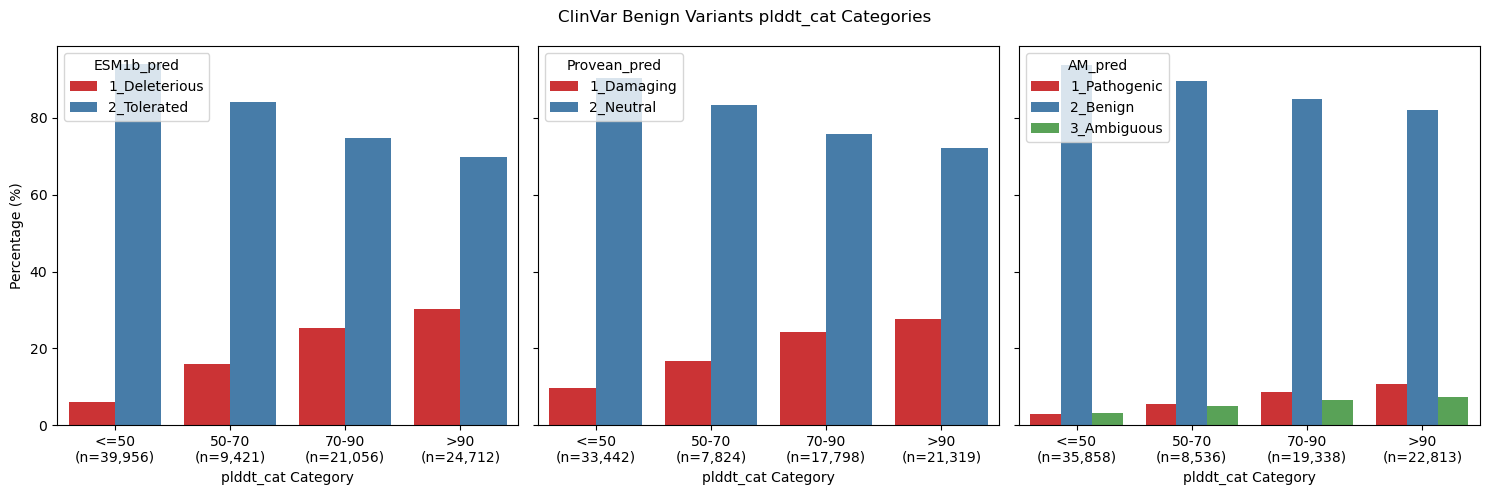

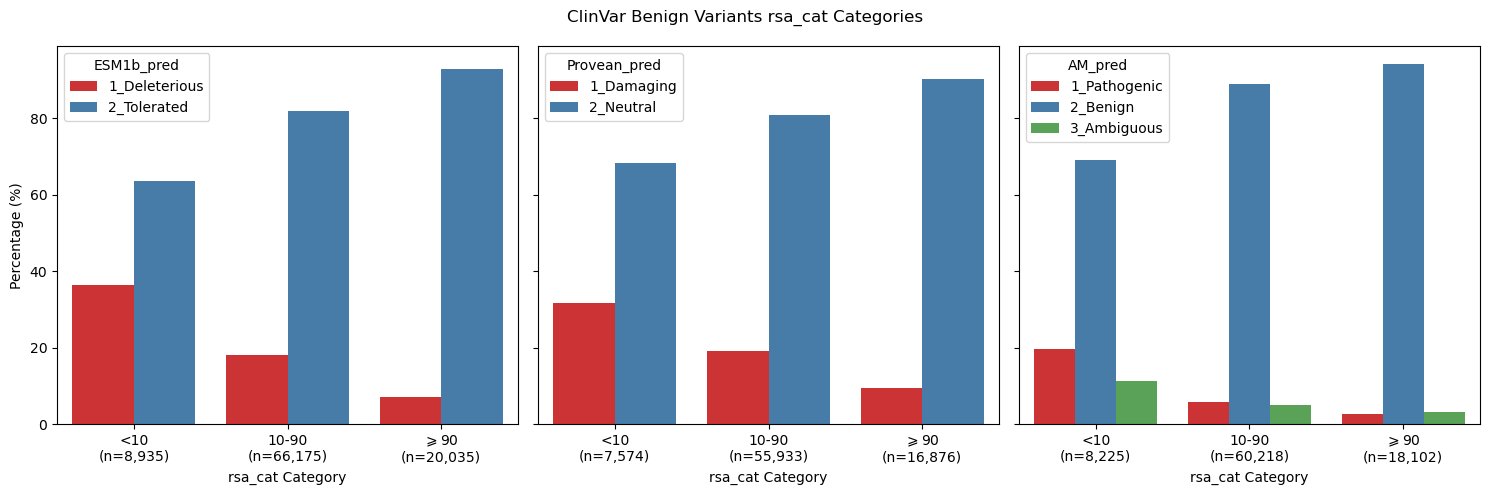

In [16]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# First, calculate the percentages for each group
# Group by both categories and calculate the percentage of each alphamissense_pred within each group

pred_cat = {
    # Make sure the categories are in the right order
    "plddt_cat": ["<=50", "50-70", "70-90", ">90"],
    "rsa_cat": ["<10", "10-90", "$\geqslant$90"]
}
preds = ["ESM1b_pred", "Provean_pred", "AM_pred"]

for cat in ["plddt_cat", "rsa_cat"]:
    fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
    for pred in preds:
        percentage_df = (
            df_clinvar_w_scores
            .filter((pl.col("clinvar_clnsig_clean")=="2_Benign")&(pl.col(pred)!="."))
            .group_by([cat, pred]) ##"RSA_cat", 
            .agg(count=pl.len())
            .collect()
            .to_pandas()  # Convert to pandas for easier use with seaborn
        )
        # Calculate percentage within each pLDDT_cat and RSA_cat group
        percentage_df['total'] = percentage_df.groupby([cat])['count'].transform('sum') ##, 'RSA_cat'
        percentage_df['percentage'] = percentage_df['count'] / percentage_df['total'] * 100
        
        # Filter for just this RSA category
        subset = percentage_df
        
        # Create the stacked barplot
        sns.barplot(
            x=cat, 
            y="percentage", 
            hue=pred,
            hue_order=sorted(percentage_df[pred].unique()),
            data=subset,
            order=pred_cat[cat],
            palette="Set1",  # You can choose a different color palette,
            ax=axes[preds.index(pred)]
        )
        # Get the current x-tick labels
        current_ticks = axes[preds.index(pred)].get_xticks()
        new_labels = []
        # For each category, add the total count to the label
        for category in pred_cat[cat]:
            # Get the total for this category
            total = subset[subset[cat] == category]['total'].iloc[0]
            # Create new label with category and total
            new_label = f"{category}\n(n={total:,})"
            new_labels.append(new_label)

        # Set the new x-tick labels
        # Explicitly set the tick positions and then the labels
        axes[preds.index(pred)].set_xticks(current_ticks[:len(new_labels)])
        axes[preds.index(pred)].set_xticklabels(new_labels)
        
        axes[preds.index(pred)].set_xlabel(f"{cat} Category")
        axes[preds.index(pred)].set_ylabel("")
        axes[preds.index(pred)].legend(loc="upper left", title=pred)

    axes[0].set_ylabel("Percentage (%)")
    # plt.legend(title="AlphaMissense Prediction")
    plt.suptitle(f"ClinVar Benign Variants {cat} Categories")
    plt.tight_layout()
    plt.show()

### PR curves per pLDDT and RSA category

In [ ]:
df_clinvar_w_scores = df_clinvar_w_scores.with_columns(
    (
        pl.when(pl.col("AlphaMissense_pred").str.contains("1_Pathogenic"))
        .then(pl.lit("1_Pathogenic"))
        .when(pl.col("AlphaMissense_pred").str.contains("2_Benign"))
        .then(pl.lit("2_Benign"))
        # .when(pl.col("AlphaMissense_pred").str.contains("A"))
        # .then(pl.lit("3_Ambiguous"))
        .otherwise(pl.lit("."))
    ).alias("AlphaMissense_ClinVar"),
    (
        pl.when(pl.col("Provean_pred").str.contains("1_Damaging"))
        .then(pl.lit("1_Pathogenic"))
        .when(pl.col("Provean_pred").str.contains("2_Neutral"))
        .then(pl.lit("2_Benign"))
        .otherwise(pl.lit("."))
    ).alias("Provean_ClinVar"),
    (
        pl.when(pl.col("ESM1b_pred").str.contains("1_Deleterious"))
        .then(pl.lit("1_Pathogenic"))
        .when(pl.col("ESM1b_pred").str.contains("2_Tolerated"))
        .then(pl.lit("2_Benign"))
        .otherwise(pl.lit("."))
    ).alias("ESM1b_ClinVar")
)

df_clinvar_w_scores = df_clinvar_w_scores.collect()

__1. AlphaMissense_score:__

AlphaMissense is a unsupervised model for predicting the pathogenicity of human missense variants
	by incorporating structural context of an AlphaFold-derived system. The AlphaMissense score ranges from 0 to 1. 
	__The larger the score, the more likely the variant is pathogenic.__

__2. ESM1b_score:__

ESM1b scores are log-likelihood ratio (LLR) scores for predicting the pathogenic effects of coding
	variants based on a 650-million-parameter protein language model, ESM1b. The range of ESM1b score in dbNSFP 
	is from -24.538 to 6.937. 
	__The smaller the score, the more likely the variant is pathogenic.__


__3. PROVEAN_score:__

PROVEAN score (PROVEANori). Scores range from -14 to 14. 
	__The smaller the score the more likely the SNP has damaging effect.__

Text(0, 0.5, 'Precision')

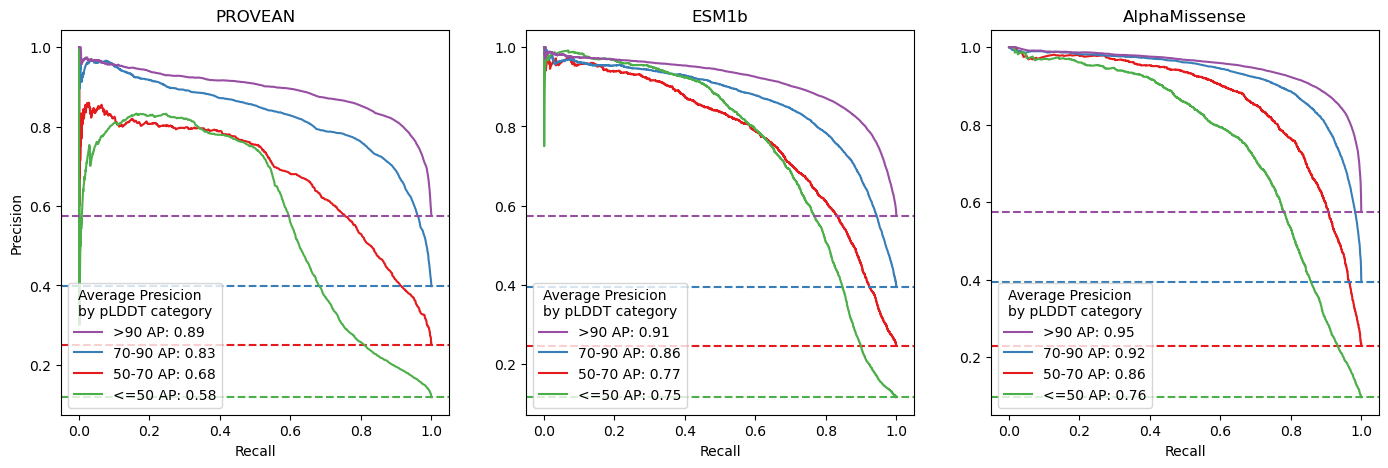

In [50]:
from sklearn.metrics import precision_recall_curve, average_precision_score

set2_palette = sns.color_palette("Set1")
methods = ["PROVEAN_converted_rankscore","ESM1b_rankscore","AlphaMissense_rankscore"]
# method_pos_label = {
#     "esm1b": 0,
#     "alphamissense": 1,
#     "provean": 0
# }

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for met in methods:
    plddt_cats = sorted(df_clinvar_w_scores["plddt_cat"].unique().to_list())
    for cat in plddt_cats:
        df_clin_per_method = df_clinvar_w_scores.filter(
            (pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic", "2_Benign"]))&(pl.col("plddt_cat")==cat)
        ).with_columns(
            (
                pl.when(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")
                .then(1) ## method_pos_label[met]
                .otherwise(0) ## 1-method_pos_label[met]
            ).alias("clinvar_label"),
            (
                pl.col(met).replace(".", None).cast(pl.Float64)
            ).alias(met)
        ).drop_nulls(
            subset=["clinvar_clnsig_clean", met]
        )
        precision, recall, thresholds = precision_recall_curve(df_clin_per_method["clinvar_label"], df_clin_per_method[met])
        ap = average_precision_score(df_clin_per_method["clinvar_label"], 
                                     df_clin_per_method[met])
        axes[methods.index(met)].plot(recall, precision, label=f"{cat} AP: {ap:.2f}", color=set2_palette[plddt_cats.index(cat)]) ## marker='.', 
        chance_level = df_clin_per_method["clinvar_label"].sum() / df_clin_per_method.shape[0]
        axes[methods.index(met)].axhline(y=chance_level, color=set2_palette[plddt_cats.index(cat)], ls="--")

    handles, labels = axes[methods.index(met)].get_legend_handles_labels()
    # print(labels)
    order = [3,1,0,2]
    axes[methods.index(met)].legend([handles[idx] for idx in order], [labels[idx] for idx in order], 
                                    title="Average Presicion\nby pLDDT category",
                                    loc="lower left")
    axes[methods.index(met)].set_xlabel('Recall')
    axes[methods.index(met)].set_title(met.split("_")[0])

axes[0].set_ylabel('Precision')
# axes[0].legend(loc="lower left", hue_order=[">90","70-90","50-70","<=50"])

In [33]:
def balance_prec(ppv, prior):
    """
    Adjusts the observed precision (ppv) to account for the base rate (prior)
    using the formula:
      balanced_precision = ppv * (1 - prior) / (ppv * (1 - prior) + (1 - ppv) * prior)
    """
    return ppv * (1 - prior) / (ppv * (1 - prior) + (1 - ppv) * prior)


def monotonize(arr):
    """
    Force the array to be non-decreasing.
    For each index i, if arr[i] < arr[i-1] then set arr[i] = arr[i-1].
    """
    arr_mono = np.copy(arr)
    for i in range(1, len(arr_mono)):
        if arr_mono[i] < arr_mono[i - 1]:
            arr_mono[i] = arr_mono[i - 1]
    return arr_mono


def calc_auc(x, y):
    """
    Calculates the area under a curve using the trapezoidal rule.
    """
    return np.trapz(y, x)


# def compute_pr_table(y_true, scores):
#     """
#     Computes a table of performance measures at various thresholds.
#     Returns a DataFrame with columns: threshold, tp, fp, fn, tn, precision, recall.
#     """
#     # Create a set of thresholds, including -infinity (all predicted positive)
#     # and +infinity (none predicted positive)
#     thresholds = np.concatenate(([-np.inf], np.sort(scores), [np.inf]))
#     rows = []
#     for t in thresholds:
#         preds = (scores >= t)
#         tp = np.sum((preds == 1) & (y_true == 1))
#         fp = np.sum((preds == 1) & (y_true == 0))
#         fn = np.sum((preds == 0) & (y_true == 1))
#         tn = np.sum((preds == 0) & (y_true == 0))
#         # Define precision as 1 when no positives are predicted (conventional choice)
#         precision = tp / (tp + fp) if (tp + fp) > 0 else 1.0
#         recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
#         rows.append({'threshold': t, 'tp': tp, 'fp': fp, 'fn': fn, 'tn': tn,
#                      'precision': precision, 'recall': recall})
#     return pd.DataFrame(rows)

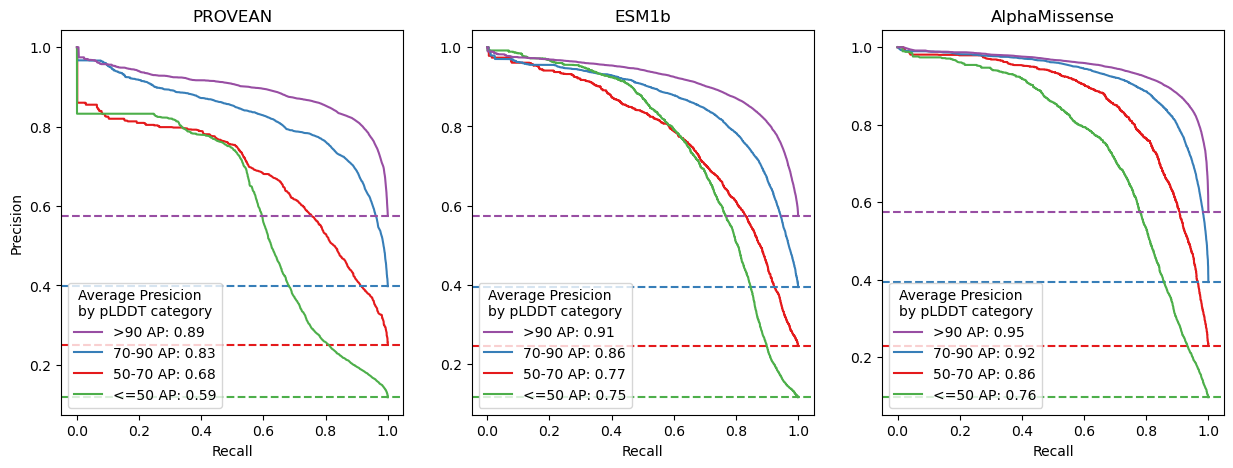

In [52]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for met in methods:
    plddt_cats = sorted(df_clinvar_w_scores["plddt_cat"].unique().to_list())
    for cat in plddt_cats:
        df_clin_per_method = df_clinvar_w_scores.filter(
            (pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic", "2_Benign"]))&(pl.col("plddt_cat")==cat)
        ).with_columns(
            (
                pl.when(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")
                .then(1) ## method_pos_label[met]
                .otherwise(0) ## 1-method_pos_label[met]
            ).alias("clinvar_label"),
            (
                pl.col(met).replace(".", None).cast(pl.Float64)
            ).alias(met)
        ).drop_nulls(
            subset=["clinvar_clnsig_clean", met]
        )

        # Compute performance table over thresholds.
        precision, recall, thresholds = precision_recall_curve(df_clin_per_method["clinvar_label"], 
                                                               df_clin_per_method[met])
        # For a fair baseline, use the first row (threshold = -∞; all predicted positive)
        prior = df_clin_per_method["clinvar_label"].sum() / df_clin_per_method.shape[0]
        
        # Adjust precision using the balance_prec function.
        precision_balanced = [balance_prec(p, prior) for p in precision]

        pr_table = pd.DataFrame({
            "recall": recall,
            "precision": precision,
            "balanced_prec": precision_balanced
        })

        # Optionally monotonize the balanced precision to smooth out dips.
        # pr_table = pr_table.sort_values('recall', ascending=False)
        pr_table['mono_precision'] = monotonize(pr_table['precision'].values)
        pr_table['mono_balanced_precision'] = monotonize(pr_table['balanced_prec'].values)

        ap = calc_auc(-pr_table["recall"].values, pr_table['mono_precision'].values)
        axes[methods.index(met)].plot(pr_table["recall"], pr_table["mono_precision"], 
                                      label=f"{cat} AP: {ap:.2f}", color=set2_palette[plddt_cats.index(cat)]) ## marker='.', 
        chance_level = df_clin_per_method["clinvar_label"].sum() / df_clin_per_method.shape[0]
        axes[methods.index(met)].axhline(y=chance_level, color=set2_palette[plddt_cats.index(cat)], ls="--")
    
    handles, labels = axes[methods.index(met)].get_legend_handles_labels()
    # print(labels)
    order = [3,1,0,2]
    axes[methods.index(met)].legend([handles[idx] for idx in order], [labels[idx] for idx in order], 
                                    loc="lower left",
                                    title="Average Presicion\nby pLDDT category")
    axes[methods.index(met)].set_xlabel('Recall')
    axes[methods.index(met)].set_title(met.split("_")[0])

axes[0].set_ylabel('Precision')
plt.subplots_adjust(wspace=0.2)

['$\\geqslant$90 AP: 0.42', '10-90 AP: 0.79', '<10 AP: 0.93']
['$\\geqslant$90 AP: 0.66', '10-90 AP: 0.84', '<10 AP: 0.94']
['$\\geqslant$90 AP: 0.67', '10-90 AP: 0.90', '<10 AP: 0.96']


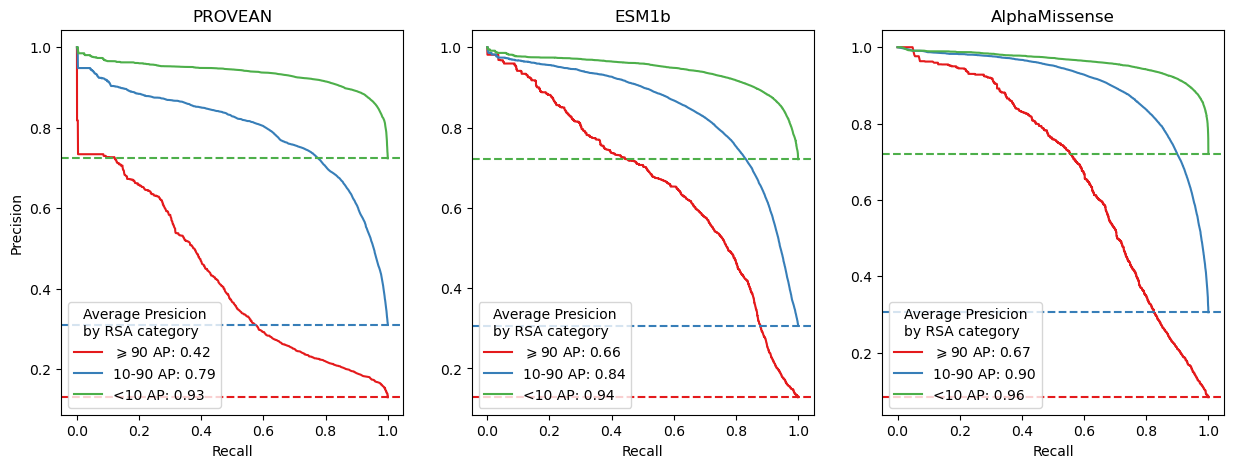

In [55]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for met in methods:
    plddt_cats = sorted(df_clinvar_w_scores["rsa_cat"].unique().to_list())
    for cat in plddt_cats:
        df_clin_per_method = df_clinvar_w_scores.filter(
            (pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic", "2_Benign"]))&(pl.col("rsa_cat")==cat)
        ).with_columns(
            (
                pl.when(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")
                .then(1) ## method_pos_label[met]
                .otherwise(0) ## 1-method_pos_label[met]
            ).alias("clinvar_label"),
            (
                pl.col(met).replace(".", None).cast(pl.Float64)
            ).alias(met)
        ).drop_nulls(
            subset=["clinvar_clnsig_clean", met]
        )

        # Compute performance table over thresholds.
        precision, recall, thresholds = precision_recall_curve(df_clin_per_method["clinvar_label"], 
                                                               df_clin_per_method[met])
        # For a fair baseline, use the first row (threshold = -∞; all predicted positive)
        prior = df_clin_per_method["clinvar_label"].sum() / df_clin_per_method.shape[0]
        
        # Adjust precision using the balance_prec function.
        precision_balanced = [balance_prec(p, prior) for p in precision]

        pr_table = pd.DataFrame({
            "recall": recall,
            "precision": precision,
            "balanced_prec": precision_balanced
        })

        # Optionally monotonize the balanced precision to smooth out dips.
        # pr_table = pr_table.sort_values('recall', ascending=False)
        pr_table['mono_precision'] = monotonize(pr_table['precision'].values)
        pr_table['mono_balanced_precision'] = monotonize(pr_table['balanced_prec'].values)

        ap = calc_auc(-pr_table["recall"].values, pr_table['mono_precision'].values)
        axes[methods.index(met)].plot(pr_table["recall"], pr_table["mono_precision"], 
                                      label=f"{cat} AP: {ap:.2f}", color=set2_palette[plddt_cats.index(cat)]) ## marker='.', 
        chance_level = df_clin_per_method["clinvar_label"].sum() / df_clin_per_method.shape[0]
        axes[methods.index(met)].axhline(y=chance_level, color=set2_palette[plddt_cats.index(cat)], ls="--")
    
    handles, labels = axes[methods.index(met)].get_legend_handles_labels()
    print(labels)
    order = [0,1,2]
    axes[methods.index(met)].legend([handles[idx] for idx in order], [labels[idx] for idx in order], 
                                    loc="lower left",
                                    title="Average Presicion\nby RSA category")
    axes[methods.index(met)].set_xlabel('Recall')
    axes[methods.index(met)].set_title(met.split("_")[0])

axes[0].set_ylabel('Precision')
plt.subplots_adjust(wspace=0.2)